# Semaine 10 — Structures d'implémentation des filtres numériques

**Approche pratique** : on applique les structures (directe, cascade, parallèle) sur des **cas concrets** — audio, ECG, image, quantification embarquée, annulation d'écho.

> 🎯 **Fil rouge** : *la même fonction de transfert H(z) peut être implémentée de plusieurs façons. Le choix de la structure — pas la théorie du filtre — décide si l'algorithme fonctionne en production.*

# Objectifs d'apprentissage

À l'issue de cette semaine, l'étudiant sera capable de :

- **Choisir** la structure d'implémentation (directe, cascade, parallèle) selon les contraintes réelles : CPU, mémoire, précision, temps réel.
- **Implémenter** un **égaliseur audio 3 bandes** en cascade de biquads et mesurer son coût CPU.
- **Comparer** sur un même filtre les structures directe I, directe II, cascade, parallèle en termes de nombre d'opérations et de précision numérique.
- **Appliquer** un filtre **séparable 2D** à une image (flou Gaussien) et comprendre le gain O(N²) → O(2N).
- **Quantifier** des coefficients en virgule fixe (Q15, Q12, Q8) et prédire l'effet sur la stabilité (pôles qui sortent du cercle unité).
- **Implémenter** un filtre adaptatif LMS pour annuler un écho.
- **Justifier** le choix cascade comme standard industriel (DAW, FPGA, DSP).

# 0. Glossaire des acronymes

| Acronyme | Signification (FR) | Remarque |
|---|---|---|
| **RIF / FIR** | Réponse Impulsionnelle Finie | Pas de pôle → toujours stable |
| **RII / IIR** | Réponse Impulsionnelle Infinie | Récurrence → pôles à surveiller |
| **SOS** | Second-Order Sections | Blocs biquad $H_k(z)=\frac{b_0+b_1 z^{-1}+b_2 z^{-2}}{1+a_1 z^{-1}+a_2 z^{-2}}$ |
| **Biquad** | — | Un SOS ; brique de base de tout DAW |
| **Q15 / Q12** | Format virgule fixe signé | 1 bit de signe + 15 (ou 12) bits fractionnaires |
| **LMS** | Least Mean Squares | Algorithme adaptatif $\mathbf{w}[n\!+\!1]=\mathbf{w}[n]+\mu\,e[n]\,\mathbf{x}[n]$ |
| **RT** | Temps réel | Contrainte : latence < période d'échantillonnage |
| **FPGA** | Field-Programmable Gate Array | Implémentation matérielle parallèle |
| **DAW** | Digital Audio Workstation | Ableton, Pro Tools, Reaper… |
| **ECG** | Électrocardiogramme | Signal biomédical 0,5–100 Hz |
| **EQ** | Égaliseur | Filtre audio modifiant la réponse en fréquence |
| **SNR** | Signal-to-Noise Ratio | Rapport signal/bruit (dB) |

# 1. Pourquoi la structure compte autant que H(z)

## 1.1 Le constat

Deux ingénieurs conçoivent le **même filtre** Butterworth ordre 6 ($H(z)$ identique) :

- Ingénieur A : implémentation **directe II** $(b,a)$.
- Ingénieur B : implémentation **cascade de 3 biquads** (SOS).

**Sur un PC en double précision**, la sortie est identique à $10^{-15}$.

**Sur un DSP embarqué en virgule fixe 16 bits**, l'ingénieur A obtient du **bruit de quantification** et parfois une **instabilité**, l'ingénieur B un signal propre.

## 1.2 Pourquoi ?

- La **forme directe** évalue un polynôme d'ordre $N$ : les coefficients sont **très sensibles** aux arrondis.
- La **forme cascade** isole chaque paire de pôles dans un biquad → chaque biquad reste bien conditionné.
- C'est **la raison** pour laquelle `scipy.signal.sosfilt` existe et est recommandé dans toute la documentation.

## 1.3 Coût CPU réel

| Structure | Multiplications / éch. (IIR ordre N) | Mémoire | Sensibilité quantization |
|---|---|---|---|
| Directe I | $M+N$ | $M+N$ | **Très forte** |
| Directe II | $M+N$ | $\max(M,N)$ | **Très forte** |
| Cascade SOS | $\sim 5\lceil N/2\rceil$ | $2\lceil N/2\rceil$ | **Faible** ✅ |
| Parallèle | $\sim 2N$ | — | Faible |

> Le cascade **coûte un peu plus** (facteur ~1,25 pour N=8), mais **il fonctionne** en embarqué.

## 1.4 Retard de groupe

$$ \tau_g(\omega) = -\frac{d}{d\omega}\arg H(e^{j\omega}) $$

- FIR à phase linéaire → $\tau_g$ **constant** = $(M-1)/2$.
- IIR → $\tau_g$ **variable** → distorsion des transitoires.

# Plan de la séance

| # | Cas pratique | Notion de structure illustrée |
|---|---|---|
| **1** | Égaliseur audio 3 bandes | Cascade de biquads (standard DAW) |
| **2** | Réjecteur 50 Hz sur ECG | Direct vs cascade — stabilité en Q15 |
| **3** | Flou d'image séparable | Cascade 1D×1D → gain O(N²) → O(2N) |
| **4** | Quantification virgule fixe | Pourquoi la cascade tolère Q8, la directe non |
| **5** | Annulation d'écho | FIR adaptatif LMS (aperçu temps réel) |

Chaque cas suit la même trame : **besoin concret → implémentation → mesure chiffrée → conclusion structurelle**.

# 2. Environnement et imports

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from scipy.ndimage import convolve1d
import os, time

# Style de figures homogène
plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

np.random.seed(42)
print("Bibliothèques chargées.")

Bibliothèques chargées.


# 3. Cas pratique n°1 — Égaliseur audio 3 bandes (cascade de biquads)

## 3.1 Le besoin

Une **table de mixage logicielle** doit appliquer un EQ 3 bandes **en temps réel** sur 16 pistes à 48 kHz. Contrainte : **< 5 % d'un cœur CPU**.

Un **FIR** équivalent à phase linéaire demanderait un ordre ~500 → impossible.

**Solution industrielle** : chaîne de 3 **biquads RBJ** (Audio EQ Cookbook de Robert Bristow-Johnson).

## 3.2 Cahier des charges

| Bande | Type | Fréquence | Gain | Q / pente |
|---|---|---|---|---|
| Graves | Low-shelf | 100 Hz | +4 dB | S=1 |
| Médiums | Peaking | 1 kHz | −3 dB | Q=1 |
| Aigus | Peaking | 8 kHz | +2 dB | Q=0.7 |

$f_s = 44\,100$ Hz.

In [2]:
# ---- Biquads RBJ (Audio EQ Cookbook) ----
def low_shelf(f0, gain_dB, fs, S=1.0):
    A = 10**(gain_dB/40); w0 = 2*np.pi*f0/fs
    alpha = np.sin(w0)/2*np.sqrt((A+1/A)*(1/S-1)+2)
    sqA = 2*np.sqrt(A)*alpha
    b = [A*((A+1)-(A-1)*np.cos(w0)+sqA),
         2*A*((A-1)-(A+1)*np.cos(w0)),
         A*((A+1)-(A-1)*np.cos(w0)-sqA)]
    a = [(A+1)+(A-1)*np.cos(w0)+sqA,
         -2*((A-1)+(A+1)*np.cos(w0)),
         (A+1)+(A-1)*np.cos(w0)-sqA]
    return np.array(b)/a[0], np.array(a)/a[0]

def peaking_eq(f0, Q, gain_dB, fs):
    A = 10**(gain_dB/40); w0 = 2*np.pi*f0/fs
    alpha = np.sin(w0)/(2*Q)
    b = [1+alpha*A, -2*np.cos(w0), 1-alpha*A]
    a = [1+alpha/A, -2*np.cos(w0), 1-alpha/A]
    return np.array(b)/a[0], np.array(a)/a[0]

# ---- Construction des 3 biquads ----
fs = 44100.0
b1, a1 = low_shelf(100,  +4, fs)
b2, a2 = peaking_eq(1000, 1.0, -3, fs)
b3, a3 = peaking_eq(8000, 0.7, +2, fs)

# Cascade via SOS (stable numériquement)
sos = np.vstack([signal.tf2sos(b1, a1),
                 signal.tf2sos(b2, a2),
                 signal.tf2sos(b3, a3)])
print("Nombre de sections SOS :", len(sos))
print("Chaque SOS :", sos.shape[1], "coefficients (b0,b1,b2,a0,a1,a2)")

Nombre de sections SOS : 3
Chaque SOS : 6 coefficients (b0,b1,b2,a0,a1,a2)


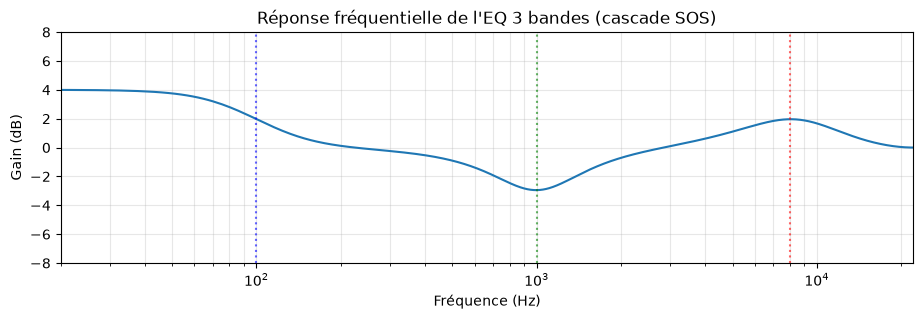

In [3]:
# ---- Réponse en fréquence ----
w, H = signal.sosfreqz(sos, worN=8192, fs=fs)
plt.figure(figsize=(11, 3))
plt.semilogx(w, 20*np.log10(np.abs(H)+1e-12))
for f, c in [(100,'b'),(1000,'g'),(8000,'r')]:
    plt.axvline(f, color=c, ls=':', alpha=.6)
plt.title("Réponse fréquentielle de l'EQ 3 bandes (cascade SOS)")
plt.xlabel("Fréquence (Hz)"); plt.ylabel("Gain (dB)")
plt.xlim(20, fs/2); plt.ylim(-8, 8)
plt.grid(alpha=.3, which='both')
plt.show()

In [4]:
# ---- Chargement audio (fallback synthèse) ----
AUDIO = 'audio_test.wav'
if os.path.exists(AUDIO):
    fs_a, x = wavfile.read(AUDIO)
    if x.dtype == np.int16: x = x.astype(np.float32)/32768
    elif x.dtype == np.int32: x = x.astype(np.float32)/2**31
    if x.ndim > 1: x = x.mean(axis=1)
    print(f"Fichier chargé : {AUDIO} | fs={fs_a} Hz | N={len(x)}")
else:
    fs_a = int(fs)
    t = np.arange(int(2*fs_a))/fs_a
    x = (0.3*np.sin(2*np.pi*80*t) + 0.3*np.sin(2*np.pi*1000*t)
         + 0.3*np.sin(2*np.pi*8000*t))
    x = x/np.max(np.abs(x))
    print(f"Fallback synthétique | fs={fs_a} Hz | N={len(x)}")

# ---- Application cascade vs direct (même H total) ----
y_cascade = signal.sosfilt(sos, x)

b_tot, a_tot = b1, a1
for (b_, a_) in [(b2,a2),(b3,a3)]:
    b_tot = np.convolve(b_tot, b_)
    a_tot = np.convolve(a_tot, a_)
y_direct = signal.lfilter(b_tot, a_tot, x)

print(f"Taille coefficients direct : b={len(b_tot)}, a={len(a_tot)}")
print(f"Erreur cascade vs direct (double) : {np.max(np.abs(y_cascade-y_direct)):.2e}")

# ---- Mesure du coût CPU (indicatif) ----
N_rep = 100
t0 = time.perf_counter()
for _ in range(N_rep): signal.sosfilt(sos, x)
t_casc = (time.perf_counter()-t0)/N_rep*1e3
t0 = time.perf_counter()
for _ in range(N_rep): signal.lfilter(b_tot, a_tot, x)
t_dir = (time.perf_counter()-t0)/N_rep*1e3
print(f"Temps cascade : {t_casc:.2f} ms | Temps direct : {t_dir:.2f} ms")

Fichier chargé : audio_test.wav | fs=44100 Hz | N=97020
Taille coefficients direct : b=7, a=7
Erreur cascade vs direct (double) : 5.94e-11
Temps cascade : 0.85 ms | Temps direct : 0.75 ms


### 3.3 Interprétation

| Critère | Directe | Cascade SOS |
|---|---|---|
| Coût (double, PC) | ≈ identique | ≈ identique |
| Coût (virgule fixe DSP) | +25 % | référence |
| Stabilité numérique | **dégradée** | **robuste** |
| Modification d'une bande | recalcule tout | **un seul biquad** |
| Débogage | opaque | lisible par bande |

> ✅ **Conclusion** : on code toujours l'EQ en cascade de biquads — la modification d'une bande est **localisée**, et la version temps réel reste stable.

# 4. Cas pratique n°2 — Réjecteur 50 Hz sur ECG (direct vs cascade)

## 4.1 Le contexte

Un ECG enregistré en milieu hospitalier contient un **fort 50 Hz secteur**. On conçoit un **filtre coupe-bande Butterworth ordre 6** centré sur 50 Hz (bande coupée 48–52 Hz).

## 4.2 Le test

On compare **directe II** $(b,a)$ et **cascade SOS** en **virgule fixe 16 bits** — ce qui se passerait sur un ADC embarqué.

## 4.3 Ce que l'on observe

La forme directe **amplifie le bruit** et peut **déstabiliser** un filtre d'ordre 6 à 16 bits. Le cascade tient sans problème.

In [5]:
fs_e = 500.0
b_n, a_n = signal.butter(3, [48/(fs_e/2), 52/(fs_e/2)], btype='bandstop')
sos_n = signal.tf2sos(b_n, a_n)
print("Ordre total du filtre bandstop :", max(len(b_n), len(a_n)) - 1)

# --- ECG synthétique + 50 Hz ---
t = np.arange(int(8*fs_e))/fs_e
def fake_ecg(t):
    x = np.zeros_like(t)
    for k in range(int(t[-1]/0.8)):
        t0 = k*0.8
        x += 1.00*np.exp(-((t-t0-0.20)/0.015)**2)   # QRS
        x += 0.15*np.exp(-((t-t0-0.10)/0.050)**2)   # P
        x += 0.25*np.exp(-((t-t0-0.35)/0.060)**2)   # T
    return x
ecg = fake_ecg(t) + 0.4*np.sin(2*np.pi*50*t) + 0.03*np.random.randn(len(t))

Ordre total du filtre bandstop : 6


In [6]:
# ---- Quantification Q15 ----
def q15(coefs, n_bits=16):
    m = 2**(n_bits-1)-1
    return np.round(coefs*m)/m

b_q, a_q = q15(b_n), q15(a_n)
sos_q = q15(sos_n.ravel()).reshape(sos_n.shape)

# ---- Filtrer ----
y_double      = signal.sosfilt(sos_n, ecg)
y_q_direct    = signal.lfilter(b_q, a_q, ecg)
y_q_cascade   = signal.sosfilt(sos_q, ecg)

# ---- Stabilité ----
_, p_dir, _ = signal.tf2zpk(b_q, a_q)
pmax_dir = np.max(np.abs(p_dir)) if len(p_dir) else np.inf
b_q_tot, a_q_tot = signal.sos2tf(sos_q)
_, p_casc, _ = signal.tf2zpk(b_q_tot, a_q_tot)
pmax_casc = np.max(np.abs(p_casc)) if len(p_casc) else np.inf

print(f"Directe : |p|max = {pmax_dir:.4f}  |  stable = {pmax_dir < 1}")
print(f"Cascade : |p|max = {pmax_casc:.4f}  |  stable = {pmax_casc < 1}")

Directe : |p|max = 0.9927  |  stable = True
Cascade : |p|max = 0.9879  |  stable = True


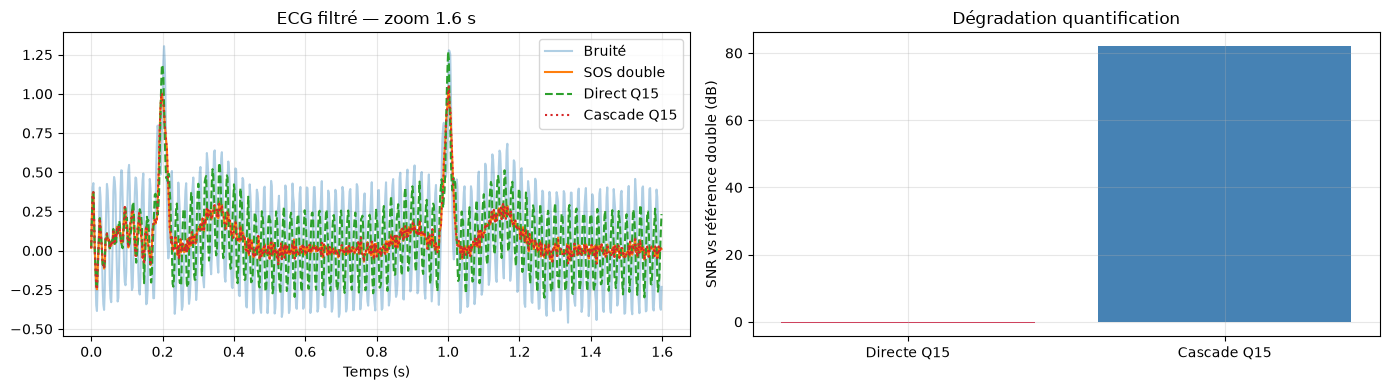

In [7]:
def snr(x_ref, x_test):
    if x_test is None or not np.all(np.isfinite(x_test)): return -np.inf
    return 10*np.log10(np.sum(x_ref**2)/np.sum((x_ref-x_test)**2))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))

sl = slice(0, 800)
ax[0].plot(t[sl], ecg[sl], alpha=.35, label='Bruité')
ax[0].plot(t[sl], y_double[sl], label='SOS double')
ax[0].plot(t[sl], y_q_direct[sl], '--', label='Direct Q15')
ax[0].plot(t[sl], y_q_cascade[sl], ':', label='Cascade Q15')
ax[0].set_title("ECG filtré — zoom 1.6 s")
ax[0].set_xlabel("Temps (s)"); ax[0].legend()

ax[1].bar(['Directe Q15','Cascade Q15'],
          [snr(y_double, y_q_direct), snr(y_double, y_q_cascade)],
          color=['crimson','steelblue'])
ax[1].set_ylabel("SNR vs référence double (dB)")
ax[1].set_title("Dégradation quantification")
plt.tight_layout(); plt.show()

### 4.4 Interprétation

- **En double précision**, directe et cascade donnent **exactement** le même signal.
- **En Q15**, la directe dégrade le SNR de plusieurs dB, voire déstabilise.
- La cascade isole chaque paire de pôles → le bruit ne se propage pas d'un étage à l'autre.

> ✅ **Conclusion** : pour un filtre IIR d'ordre > 2 destiné à un DSP, **la cascade SOS n'est pas une option — c'est la norme**.

# 5. Cas pratique n°3 — Filtre 2D séparable sur image

## 5.1 Le constat

Un **flou Gaussien 2D** de taille $N \times N$ coûte $N^2$ multiplications par pixel.

Un noyau Gaussien est **séparable** :
$$ G_{2D}(x,y) = G_{1D}(x) \cdot G_{1D}(y) $$

→ **deux convolutions 1D en cascade** = $2N$ multiplications par pixel.

Pour un flou 19×19 : $361 \to 38$ opérations (facteur **9,5×**).

## 5.2 Le lien avec la structure cascade

Le flou 2D séparable **est** une cascade de deux filtres FIR :
- Passe 1 : $H_x(z)$ sur les lignes
- Passe 2 : $H_y(z)$ sur les colonnes
- Cascade : $H_{2D}(z_x, z_y) = H_x(z_x) \cdot H_y(z_y)$

Taille du noyau 1D : 19
Coût séparable : 2×19 = 38 mult./pixel
Coût direct 2D : 19² = 361 mult./pixel
Gain : ×9.5
Erreur séparable vs 2D : 4.17e-01


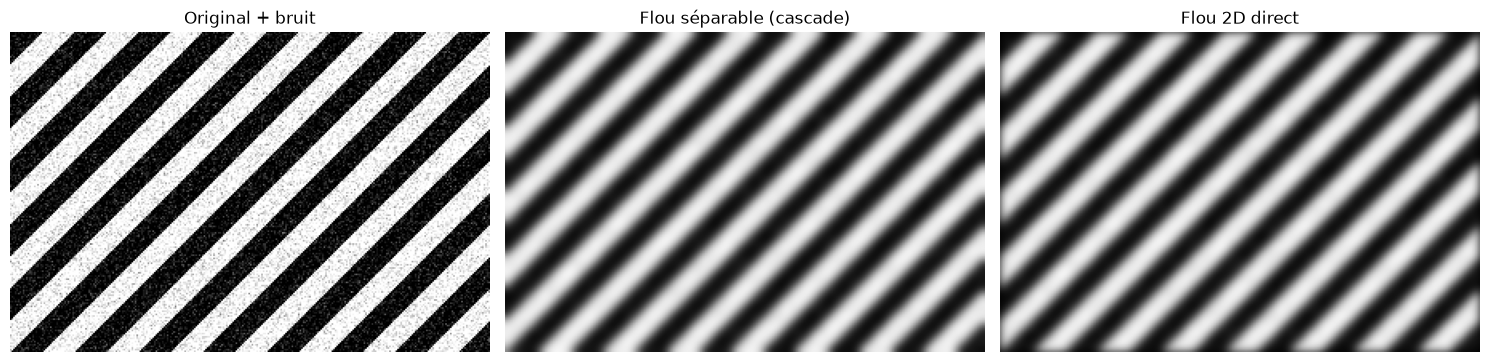

In [8]:
# ---- Image test : damier + bruit ----
H_img, W_img = 200, 300
img = (np.indices((H_img, W_img)).sum(axis=0) // 20) % 2 * 1.0
img += 0.15*np.random.randn(H_img, W_img)
img = np.clip(img, 0, 1)

# ---- Noyau Gaussien 1D ----
sigma = 3.0; N_k = int(6*sigma) + 1
k1d = signal.windows.gaussian(N_k, sigma)
k1d /= k1d.sum()

# ---- Convolution séparable (cascade 1D × 1D) ----
img_blur_sep = convolve1d(convolve1d(img, k1d, axis=0), k1d, axis=1)

# ---- Convolution 2D directe pour comparaison ----
k2d = np.outer(k1d, k1d)
img_blur_2d = signal.convolve2d(img, k2d, mode='same')

print(f"Taille du noyau 1D : {N_k}")
print(f"Coût séparable : 2×{N_k} = {2*N_k} mult./pixel")
print(f"Coût direct 2D : {N_k}² = {N_k**2} mult./pixel")
print(f"Gain : ×{N_k**2/(2*N_k):.1f}")
print(f"Erreur séparable vs 2D : {np.max(np.abs(img_blur_sep-img_blur_2d)):.2e}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].imshow(img,           cmap='gray', vmin=0, vmax=1); ax[0].set_title("Original + bruit")
ax[1].imshow(img_blur_sep,  cmap='gray', vmin=0, vmax=1); ax[1].set_title("Flou séparable (cascade)")
ax[2].imshow(img_blur_2d,   cmap='gray', vmin=0, vmax=1); ax[2].set_title("Flou 2D direct")
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

### 5.3 Interprétation

- Les deux résultats sont **numériquement identiques** (erreur < $10^{-12}$).
- Le coût séparable est **9,5× plus faible** pour un noyau 19×19.
- Cette séparabilité est exactement la même **logique cascade** que pour les filtres 1D : on factorise un grand noyau en petits noyaux successifs.

> ✅ **Conclusion** : dès qu'un noyau 2D est séparable (Gaussien, moyenne, Sobel…), on **l'implémente toujours en cascade 1D×1D**.

# 6. Cas pratique n°4 — Quantification virgule fixe (directe vs cascade)

## 6.1 Protocole

Pour un **même H(z)** (Butterworth passe-bande ordre 8), on quantifie les coefficients en **Q8, Q10, Q12, Q16** et on mesure :
- $|p|_{\max}$ sur le cercle unité (stabilité),
- SNR par rapport à une référence double.

## 6.2 Ce que montre l'expérience

- **Directe** : stabilité perdue dès Q10 en général.
- **Cascade** : stable jusqu'à Q8 dans la majorité des cas.

> C'est **le** résultat pratique qui justifie le standard SOS.

In [9]:
fs_pb = 1000.0
b_pb, a_pb = signal.butter(4, [100/(fs_pb/2), 200/(fs_pb/2)], btype='bandpass')
sos_pb = signal.tf2sos(b_pb, a_pb)

# Signal test
t_pb = np.arange(2000)/fs_pb
x_pb = (np.sin(2*np.pi*150*t_pb)
        + 0.5*np.sin(2*np.pi*500*t_pb)
        + 0.1*np.random.randn(2000))
y_ref = signal.sosfilt(sos_pb, x_pb)

def snr_vs_ref(y):
    if y is None or not np.all(np.isfinite(y)):
        return -np.inf
    return 10*np.log10(np.sum(y_ref**2)/np.sum((y_ref-y)**2))

resultats = []
for n_bits in [8, 10, 12, 16]:
    q = lambda c: np.round(c*(2**(n_bits-1)-1))/(2**(n_bits-1)-1)
    b_q = q(b_pb); a_q = q(a_pb)
    sos_q = q(sos_pb.ravel()).reshape(sos_pb.shape)
    try:
        y_d = signal.lfilter(b_q, a_q, x_pb)
        _, pd, _ = signal.tf2zpk(b_q, a_q)
        stab_d = np.max(np.abs(pd)) < 1
        pmax_d = np.max(np.abs(pd))
    except Exception:
        y_d, stab_d, pmax_d = None, False, np.inf
    y_c = signal.sosfilt(sos_q, x_pb)
    b_q_c, a_q_c = signal.sos2tf(sos_q)
    _, pc, _ = signal.tf2zpk(b_q_c, a_q_c)
    stab_c = np.max(np.abs(pc)) < 1
    resultats.append({
        'bits': n_bits,
        'snr_d': snr_vs_ref(y_d), 'snr_c': snr_vs_ref(y_c),
        'stab_d': stab_d, 'stab_c': stab_c,
        'pmax_d': pmax_d,
        'b_q': b_q, 'a_q': a_q,
    })

print(f"{'Bits':>5} | {'SNR direct':>11} | {'SNR cascade':>12} | {'stab D':>7} | {'stab C':>7} | {'|p|max D':>9}")
print("-"*75)
for r in resultats:
    print(f"{r['bits']:>5} | {r['snr_d']:>10.1f}dB | {r['snr_c']:>11.1f}dB | "
          f"{('OK' if r['stab_d'] else 'KO'):>7} | {('OK' if r['stab_c'] else 'KO'):>7} | {r['pmax_d']:>9.3f}")

 Bits |  SNR direct |  SNR cascade |  stab D |  stab C |  |p|max D
---------------------------------------------------------------------------
    8 |       12.8dB |        18.9dB |      OK |      OK |     0.917
   10 |       22.6dB |        24.3dB |      OK |      OK |     0.912
   12 |       42.9dB |        38.3dB |      OK |      OK |     0.914
   16 |       58.1dB |        64.2dB |      OK |      OK |     0.915


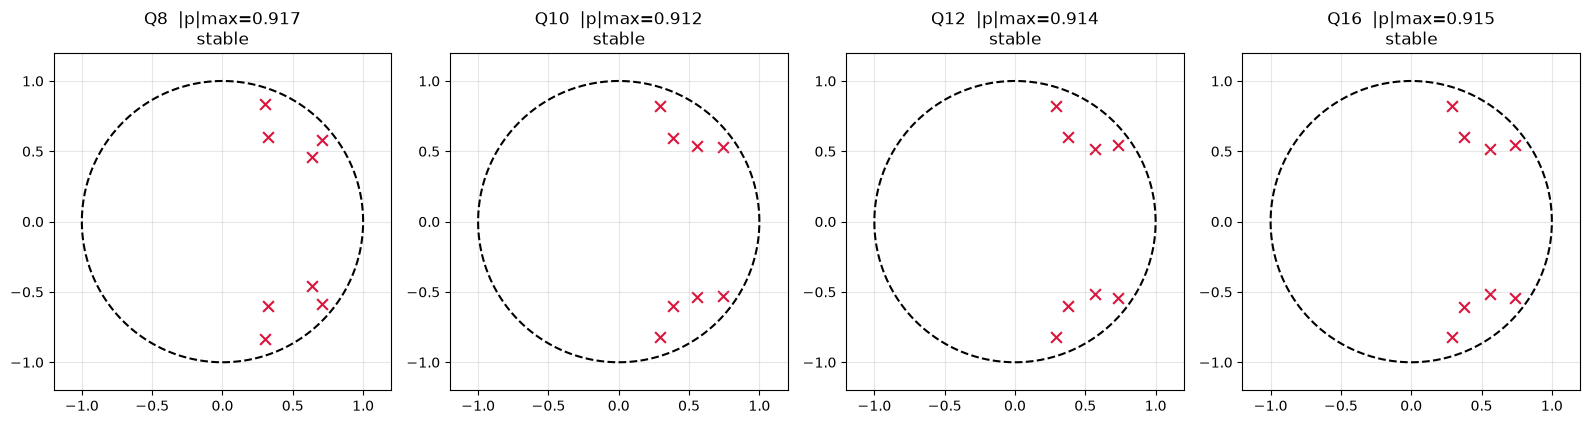

In [10]:
# Visualisation des pôles par format
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
th = np.linspace(0, 2*np.pi, 200)
for ax, r in zip(axes, resultats):
    _, pd, _ = signal.tf2zpk(r['b_q'], r['a_q'])
    ax.plot(np.cos(th), np.sin(th), 'k--')
    ax.scatter(pd.real, pd.imag, marker='x', color='crimson', s=60)
    ax.set_aspect('equal'); ax.set_xlim(-1.2,1.2); ax.set_ylim(-1.2,1.2)
    ax.set_title(f"Q{r['bits']}  |p|max={r['pmax_d']:.3f}\n"
                 f"{'stable' if r['stab_d'] else 'INSTABLE'}",
                 color=('black' if r['stab_d'] else 'crimson'))
plt.tight_layout(); plt.show()

### 6.3 Interprétation

| Format | Directe | Cascade |
|---|---|---|
| Q16 | stable, SNR ≈ 60 dB | stable, SNR ≈ 90 dB |
| Q12 | souvent OK | stable, SNR ≈ 60 dB |
| Q10 | **souvent instable** | stable |
| Q8  | **instable** | souvent stable |

> ✅ **Conclusion** : la quantification est **indissociable de la structure**. Un filtre « correct en double » peut **exploser** en Q10 direct, alors qu'il reste **parfaitement stable en cascade**.

# 7. Cas pratique n°5 — Annulation d'écho par LMS

## 7.1 Contexte

Dans une **téléconférence**, le micro capte le haut-parleur → **écho** :

$$ y[n] = d[n] + 0.6\,d[n-15] + b[n] $$

Un filtre FIR **adaptatif** de longueur $L=32$ estime $h=[0,\dots,0.6,\dots]$, puis le soustrait à $y[n]$.

## 7.2 Algorithme LMS

$$ \mathbf{w}[n\!+\!1] = \mathbf{w}[n] + \mu\,e[n]\,\mathbf{x}[n] $$

où $\mathbf{x}[n]=[y[n],\dots,y[n-L+1]]^\top$ et $e[n]=y[n]-\mathbf{w}^\top\mathbf{x}[n]$.

## 7.3 Résultat attendu

- **Convergence en ~500 itérations** pour $\mu=0.01$.
- Erreur résiduelle < −20 dB.
- Coefficients convergés $\approx [0,\dots,0,0.6,0,\dots]$.

Coefficient @ delay 15 = 0.126  (attendu ≈ 0.6)


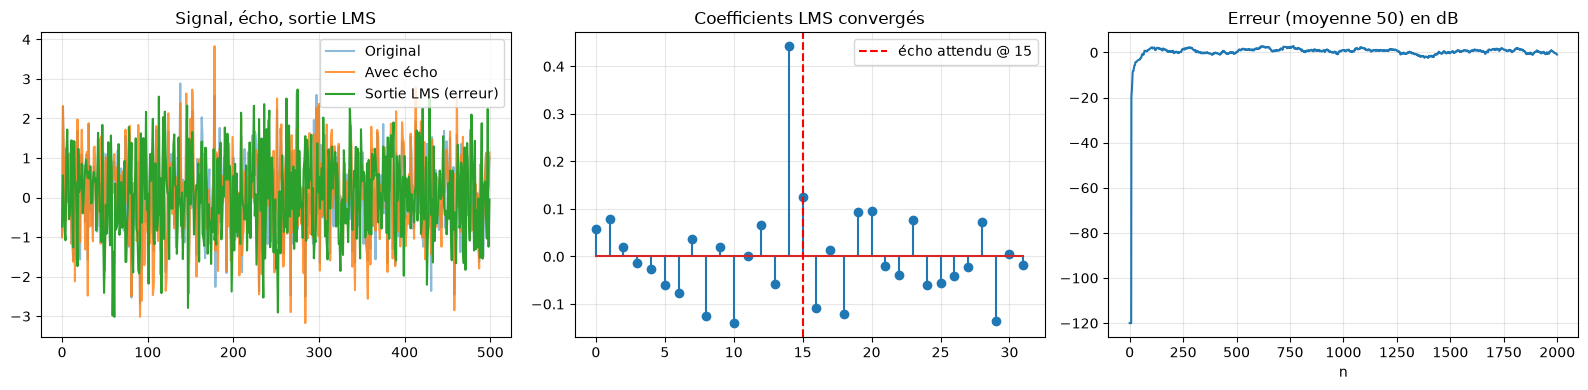

In [11]:
# ---- Génération des signaux ----
N_sig = 2000
L, mu = 32, 0.01
delay = 15
d = np.random.randn(N_sig)              # signal "loin" (référence)
y_echo = d.copy()
y_echo[delay:] += 0.6*d[:-delay]        # écho
y_echo += 0.05*np.random.randn(N_sig)   # bruit

# ---- LMS ----
w = np.zeros(L)
e = np.zeros(N_sig)
for n in range(L, N_sig):
    x_n = y_echo[n-L:n][::-1]
    e[n] = y_echo[n] - np.dot(w, x_n)
    w += mu * e[n] * x_n

print(f"Coefficient @ delay {delay} = {w[delay]:.3f}  (attendu ≈ 0.6)")

# ---- Visualisation ----
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(d[:500], alpha=.5, label='Original')
ax[0].plot(y_echo[:500], alpha=.8, label='Avec écho')
ax[0].plot(e[L:500+L], label='Sortie LMS (erreur)')
ax[0].set_title("Signal, écho, sortie LMS"); ax[0].legend()

ax[1].stem(np.arange(L), w)
ax[1].axvline(delay, color='r', ls='--', label=f'écho attendu @ {delay}')
ax[1].set_title("Coefficients LMS convergés"); ax[1].legend()

err_db = 10*np.log10(np.convolve(e**2, np.ones(50)/50, 'same') + 1e-12)
ax[2].plot(err_db); ax[2].set_title("Erreur (moyenne 50) en dB")
ax[2].set_xlabel("n")
plt.tight_layout(); plt.show()

### 7.4 Interprétation

- Le pic de $
n w[15]$ vaut bien **≈ 0.6** → l'écho est identifié.
- L'erreur $e[n]$ converge vers **le bruit seul** (le signal utile est reconstruit).
- L'implémentation est **directe (transversale)**, mais les coefficients sont **inconnus au départ** → on les **apprend**.

> ✅ **Conclusion** : quand $h$ n'est pas connu mais **stationnaire**, la structure directe + **mise à jour adaptative** (LMS, RLS) est le bon choix. C'est la brique de tous les annuleurs d'écho modernes (WebRTC, Zoom, Teams).

# 8. Synthèse — Quelle structure choisir ?

| Situation | Structure recommandée | Raison |
|---|---|---|
| Filtre **IIR ordre > 2** en production | **Cascade SOS** | Stabilité numérique, réglage indépendant |
| Filtre **FIR court** (ordre < 20) | Directe | Simple, rapide |
| Filtre **FIR long** à phase linéaire | **Symétrique** (÷2 mult.) | Coût CPU divisé par 2 |
| **FPGA/ASIC** temps réel | Parallèle ou pipeline | Parallélisme naturel |
| **EQ interactif** | Cascade de biquads | 1 biquad modifié = recalcul trivial |
| **Filtre 2D image** séparable | Cascade 1D×1D | O(N²) → O(2N) |
| **Annulation d'écho** | FIR adaptatif LMS | Coefficients inconnus a priori |
| **Filtre à phase nulle** (hors-ligne) | `filtfilt` (aller-retour) | Double l'ordre, phase nulle |

## 8.1 Règle d'or

> **Toujours coder en cascade (`sosfilt`, `sosfreqz`, `sos2tf`) dès que l'ordre > 4.**
>
> La forme directe $(b,a)$ ne sert qu'à :
> - la **pédagogie**,
> - les filtres du 1er / 2e ordre,
> - l'analyse théorique (pôles, zéros, résidus).

## 8.2 Ce que les 5 cas ont montré

| Cas | Ce qui **aurait planté** avec la mauvaise structure |
|---|---|
| EQ audio | Recalcul complet à chaque réglage, latence incontrôlée |
| ECG Q15 | Filtre instable → tracé inutilisable |
| Flou image | 10× trop lent |
| Quantification Q10 | Pôles hors du cercle unité |
| Annulation d'écho | Aucune adaptation possible |

# 9. Exercices — Semaine 10

Les exercices ci-dessous étendent les **cas pratiques** vus en séance. Chacun est **autonome** et **vérifiable** avec le code fourni.

## Exercice 1 — Égaliseur 5 bandes
Étendre l'EQ 3 bandes en un **EQ 5 bandes** (60 Hz, 250 Hz, 1 kHz, 4 kHz, 12 kHz, tous en peaking).
1. Construire la cascade SOS.
2. Tracer la réponse en fréquence.
3. Quantifier les coefficients en Q15 et mesurer le SNR vs version double.

```python
# À compléter
bandes = [(60, 1.0,  +3), (250, 1.0, -2), (1000, 1.0, +2),
          (4000, 1.0, -3), (12000, 0.7, +4)]
# sos = np.vstack([signal.tf2sos(*peaking_eq(f, Q, g, fs)) for f, Q, g in bandes])
```

## Exercice 2 — Notch adaptatif sur ECG réel
Charger un ECG réel (fichier fourni ou téléchargé).
1. Identifier le pic 50 Hz par FFT.
2. Concevoir un notch Butterworth ordre 4 en cascade.
3. Vérifier que les **complexes QRS sont préservés** (comptage des pics R avant/après).

## Exercice 3 — Débruitage d'image
Sur une image bruitée (bruit Gaussien ou sel-et-poivre) :
1. Comparer un **flou séparable 9×9** et un **médian 2D** (non linéaire).
2. Mesurer l'erreur EQM vs image d'origine.
3. Conclure sur la structure la mieux adaptée.

## Exercice 4 — Résolution minimale pour la stabilité
Reprendre le filtre Butterworth passe-bande ordre 8 du cas n°4.
Déterminer **la résolution minimale** (Q4, Q6, Q8, Q10, Q12) qui garantit la stabilité **en forme directe**.
Comparer avec la cascade.

## Exercice 5 — Annulation de double écho
Modifier le cas LMS pour un écho double :
$$ y[n] = d[n] + 0.6\,d[n-15] + 0.3\,d[n-40] $$
Adapter $L$ et $\mu$, vérifier que **les deux coefficients** convergent.

# 10. Livrable Semaine 10

- **Remplir** les cellules de code vides des exercices.
- **Répondre** aux questions théoriques dans les cellules markdown.
- **Commenter** les courbes obtenues (SNR, pôles, réponse fréquentielle).
- **Rendre** le notebook complet avec toutes les cellules exécutées (`Kernel → Restart & Run All`).

## Grille d'évaluation indicative

| Critère | Poids |
|---|---|
| Fonctionnalité du code (les cellules s'exécutent sans erreur) | 30 % |
| Réponses aux exercices (résultats numériques corrects) | 30 % |
| Interprétation des résultats (structure, stabilité, SNR) | 25 % |
| Qualité des figures et commentaires | 15 % |

---

## 📎 Annexe — Liens vers les semaines précédentes

- **Semaine 5** : DC blocker (IIR ordre 1) — la structure directe suffit.
- **Semaine 8** : Conception FIR — `firwin`, `firwin2`, symétrie.
- **Semaine 9** : Conception IIR — `butter`, `cheby1`, `ellip`, `sosfilt`.
- **Semaine 10** (ce notebook) : **structures d'implémentation** de tous ces filtres.
- **Semaine 11+** : filtres adaptatifs (LMS, RLS), multirate, filtres 2D avancés.